<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta4_g%C3%B6rev7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Canny Çalışma Zamanı: 6.57 ms


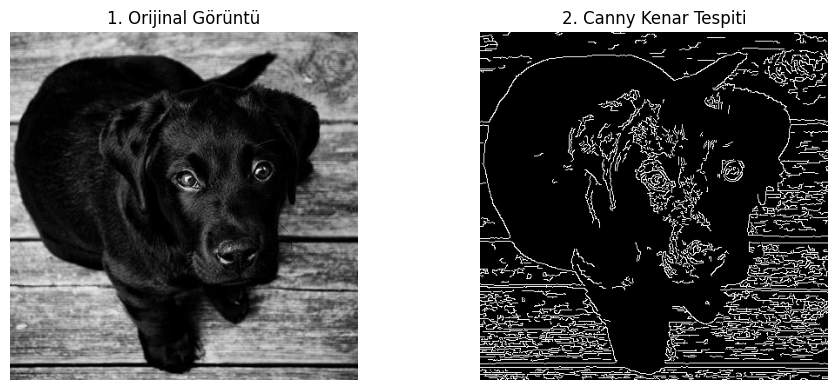

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request
import time

# 1. Test için örnek bir görüntü indirelim
url = 'https://picsum.photos/id/237/400/400'
req = urllib.request.urlopen(url)
arr = np.asarray(bytearray(req.read()), dtype=np.uint8)
img = cv2.imdecode(arr, cv2.IMREAD_GRAYSCALE)

# 2. Canny Algoritması Çalışma Zamanı Ölçümü
start_time = time.time()

# Canny otomatik olarak içine Gauss uygular, alt ve üst eşik değerleri (100, 200)
canny_img = cv2.Canny(img, 100, 200)

end_time = time.time()
canny_time = (end_time - start_time) * 1000 # milisaniye cinsinden
print(f"Canny Çalışma Zamanı: {canny_time:.2f} ms")

# 3. Sonuçları Görselleştirme
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('1. Orijinal Görüntü')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(canny_img, cmap='gray')
plt.title('2. Canny Kenar Tespiti')
plt.axis('off')

plt.tight_layout()
plt.show()

Sobel ve Prewitt: Birinci derece türev kullanırlar. Geniş hatları bulmakta başarılıdırlar ancak eşik (threshold) değeri verilmediği için gri tonlamalı gradyan haritası üretirler; yani kenarlar kalın ve bazen belirsiz kalır.

Laplacian ve LoG: İkinci derece türev aldıkları için ince detayları çok iyi yakalarlar. LoG, başındaki geniş Gauss filtresi sayesinde gürültüyü engeller ancak yine de tek piksel inceliğinde net çizgiler vermekte zorlanabilir.

Canny Algoritması: Görüntü işlemedeki en gelişmiş ve altın standart kenar tespit algoritmalarından biridir. İçerisinde sırasıyla; Gauss yumuşatması, gradyan hesaplama, yönlü inceltme (non-maximum suppression) ve çift eşikleme (hysteresis thresholding) adımlarını barındırır. Bu sayede parazitleri tamamen eler ve tek piksel kalınlığında, kopmayan net kenar çizgileri üretir.

Hız açısından tüm maske tabanlı filtreler (Sobel, Prewitt, Laplacian) ve Canny, Python/OpenCV ortamında milisaniyeler içinde çalıştığı için hız bakımından aralarında büyük bir pratik fark yoktur.

Doğruluk ve netlik açısından ise Canny algoritması, gereksiz gürültüleri temizlemesi ve kenarları tek piksel inceliğinde kusursuz bir şekilde birleştirmesi nedeniyle diğer tüm yöntemlerden açık ara üstün bir performans sergilemiştir. Bu yüzden gerçek hayat projelerinde ve bilgisayarlı görü ödevlerinde kenar tespiti için neredeyse her zaman Canny ilk tercihtir.
